#### Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from collections import Counter
from wordcloud import WordCloud

#### Loading the Dataset

In [2]:
# Loading the raw dataset
df = pd.read_csv("../data/raw/pricerunner_aggregate.csv")

# Displaying the first 10 records
df.head(10)

,Product ID,Product Title,Merchant ID,Cluster ID,Cluster Label,Category ID,Category Label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
5,6,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,6,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
6,7,apple iphone 8 plus 64 gb space grey,7,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
7,8,apple iphone 8 plus 64gb space grey,8,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
8,9,apple iphone 8 plus 64gb space grey,9,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
9,10,apple iphone 8 plus 64gb space grey,10,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


#### Visualizing Product Category Distribution

In [3]:
# Calculating category frequencies
category_counts = df[" Category Label"].value_counts().reset_index()
category_counts.columns = ["Category", "Count"]

# Creating a horizontal bar chart
fig = px.bar(
    category_counts,
    x="Count",
    y="Category",
    orientation="h",
    text="Count",
    title="Distribution of Product Listings Across Categories",
    color="Count",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_layout(
    xaxis_title="Number of Product Listings",
    yaxis_title="Product Category",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=550
)

fig.update_traces(
    textposition="outside",
    cliponaxis=False
)

fig.show()

**Observations on Product Category Distribution:**

- `Fridge Freezers` represents the largest category with **5,501 listings (15.58%)**, followed by `Mobile Phones` (11.56%) and `Washing Machines` (11.45%).
- `Freezers` (6.26%) and `Microwaves` (6.63%) have the fewest listings, indicating moderate variation in category representation.
- All 10 categories have substantial sample sizes, although macro-averaged evaluation metrics will be important for assessing classification performance fairly.

#### Visualizing Product Category Proportions

In [4]:
# Calculating category percentages
category_proportions = (
    df[" Category Label"]
    .value_counts(normalize=True)
    .mul(100)
    .reset_index()
)

category_proportions.columns = ["Category", "Percentage"]

# Creating a donut chart
fig = px.pie(
    category_proportions,
    names="Category",
    values="Percentage",
    hole=0.5,
    title="Proportion of Product Listings by Category",
    color_discrete_sequence=px.colors.qualitative.Set3
)

# Customizing the chart layout
fig.update_traces(
    textposition="inside",
    textinfo="percent",
    hovertemplate="<b>%{label}</b><br>Share: %{percent}<extra></extra>"
)

fig.update_layout(
    template="plotly_white",
    height=550,
    legend_title="Product Category",
    margin=dict(t=80, b=40, l=40, r=40)
)

fig.show()

**Observations on Product Category Proportions:**

- `Fridge Freezers` contributes the largest share of product listings at **15.58%**, followed by `Mobile Phones` (11.56%) and `Washing Machines` (11.45%).
- `Freezers` (6.26%) and `Microwaves` (6.63%) account for the smallest proportions of the dataset.
- The distribution is moderately imbalanced, with no single category dominating the dataset.

#### Visualizing Product Title Word Count Distribution

In [5]:
# Calculating the number of words in each product title
df["Title_Word_Count"] = df["Product Title"].str.split().str.len()

# Creating a histogram of product title word counts
fig = px.histogram(
    df,
    x="Title_Word_Count",
    nbins=35,
    title="Distribution of Product Title Word Counts",
    color_discrete_sequence=["#3274A1"]
)

# Customizing the chart layout
fig.update_layout(
    xaxis_title="Number of Words",
    yaxis_title="Number of Product Listings",
    template="plotly_white",
    height=500,
    bargap=0.05
)

fig.show()

**Observations on Product Title Word Count Distribution:**

- Product titles contain an average of **8.67 words**, with a median of **8 words**, indicating relatively short product descriptions.
- The middle 50% of titles contain between **6 and 11 words**, suggesting that most listings have compact text descriptions.
- Word counts range from **1 to 37**, highlighting variation in descriptive detail across product listings.

#### Visualizing Product Title Character Count Distribution

In [6]:
# Calculating the number of characters in each product title
df["Title_Character_Count"] = df["Product Title"].str.len()

# Creating a histogram of product title character counts
fig = px.histogram(
    df,
    x="Title_Character_Count",
    nbins=40,
    title="Distribution of Product Title Character Counts",
    color_discrete_sequence=["#3274A1"]
)

# Customizing the chart layout
fig.update_layout(
    xaxis_title="Number of Characters",
    yaxis_title="Number of Product Listings",
    template="plotly_white",
    height=500,
    bargap=0.05
)

fig.show()

**Observations on Product Title Character Count Distribution:**

- Product titles contain an average of **52.98 characters**, with a median of **52 characters**, indicating relatively compact descriptions.
- The middle 50% of titles range from **38 to 65 characters**, suggesting fairly consistent title lengths across most listings.
- Character counts range from **5 to 200**, reflecting differences in product naming conventions and the amount of technical information included.

#### Visualizing Average Product Title Length by Category

In [7]:
# Calculating average word counts by product category
category_word_lengths = (
    df.groupby(" Category Label")["Title_Word_Count"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

category_word_lengths.columns = ["Category", "Average Word Count"]

# Creating a horizontal bar chart
fig = px.bar(
    category_word_lengths,
    x="Average Word Count",
    y="Category",
    orientation="h",
    text="Average Word Count",
    title="Average Product Title Word Count by Category",
    color="Average Word Count",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Average Number of Words",
    yaxis_title="Product Category",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=550
)

fig.show()

**Observations on Average Product Title Length by Category:**

- `CPUs` have the longest product titles, averaging **12.42 words**, followed by `TVs` (10.25) and `Digital Cameras` (9.62).
- `Dishwashers` have the shortest titles on average (**6.81 words**), followed by `Freezers` (7.21) and `Fridges` (7.49).
- Differences in title length indicate varying levels of descriptive detail across product categories, potentially influencing text feature extraction.

#### Visualizing Product Title Word Count Variability by Category

In [8]:
# Ordering categories by median word count
category_order = (
    df.groupby(" Category Label")["Title_Word_Count"]
    .median()
    .sort_values(ascending=False)
    .index
)

# Creating a box plot of word counts by category
fig = px.box(
    df,
    x="Title_Word_Count",
    y=" Category Label",
    category_orders={" Category Label": category_order.tolist()},
    color=" Category Label",
    title="Product Title Word Count Variability by Category",
    points=False
)

# Customizing the chart layout
fig.update_layout(
    xaxis_title="Number of Words",
    yaxis_title="Product Category",
    showlegend=False,
    template="plotly_white",
    height=550
)

fig.show()

#### Inspecting Product Title Word Count Variability by Category

In [9]:
# Calculating word count statistics for each product category
word_count_summary = (
    df.groupby(" Category Label")["Title_Word_Count"]
    .agg(
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .round(2)
    .sort_values("Median", ascending=False)
)

# Displaying category-wise word count statistics
word_count_summary

,Mean,Median,Minimum,Maximum,Q1,Q3
Category Label,,,,,,
CPUs,12.42,12.0,2,29,10.0,15.0
TVs,10.25,10.0,2,31,7.0,13.0
Digital Cameras,9.62,9.0,2,36,6.0,12.0
Fridge Freezers,8.18,8.0,1,24,6.0,10.0
Microwaves,7.65,8.0,2,26,5.0,10.0
Washing Machines,7.82,8.0,2,22,6.0,10.0
Fridges,7.49,7.0,1,28,5.0,9.0
Freezers,7.21,7.0,1,24,5.0,9.0
Dishwashers,6.81,7.0,2,29,5.0,8.0


**Observations on Product Title Word Count Variability by Category:**

- `CPUs` have the highest median word count (**12 words**), followed by `TVs` (10) and `Digital Cameras` (9), indicating generally longer product descriptions.
- `TVs` and `Digital Cameras` have relatively wide interquartile ranges (**6 words**), while `Dishwashers` have a narrower range (**3 words**).
- `Mobile Phones` exhibit a notable difference between mean (8.55) and median (7) word counts, suggesting that longer descriptions influence the category average.

#### Visualizing Average Product Title Character Count by Category

In [10]:
# Calculating average character counts by product category
category_character_lengths = (
    df.groupby(" Category Label")["Title_Character_Count"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

category_character_lengths.columns = ["Category", "Average Character Count"]

# Creating a horizontal bar chart
fig = px.bar(
    category_character_lengths,
    x="Average Character Count",
    y="Category",
    orientation="h",
    text="Average Character Count",
    title="Average Product Title Character Count by Category",
    color="Average Character Count",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Average Number of Characters",
    yaxis_title="Product Category",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=550
)

fig.show()

**Observations on Average Product Title Character Count by Category:**

- `CPUs` have the longest product titles, averaging **67.03 characters**, followed by `Fridge Freezers` (55.21) and `TVs` (54.70).
- `Mobile Phones` have the shortest titles on average (**46.20 characters**), followed by `Fridges` (48.54) and `Freezers` (48.80).
- Differences in average character counts highlight variations in product naming conventions and technical specifications across categories.

#### Visualizing Most Frequent Words in Product Titles

In [11]:
# Combining product titles and calculating word frequencies
all_words = " ".join(df["Product Title"].str.lower()).split()
word_frequencies = Counter(all_words)

# Creating a dataframe of the 20 most frequent words
top_words_df = pd.DataFrame(
    word_frequencies.most_common(20),
    columns=["Word", "Frequency"]
)

# Creating a horizontal bar chart
fig = px.bar(
    top_words_df,
    x="Frequency",
    y="Word",
    orientation="h",
    text="Frequency",
    title="Top 20 Most Frequent Words in Product Titles",
    color="Frequency",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Word Frequency",
    yaxis_title="Word",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=600
)

fig.show()

#### Visualizing Product Title Word Cloud

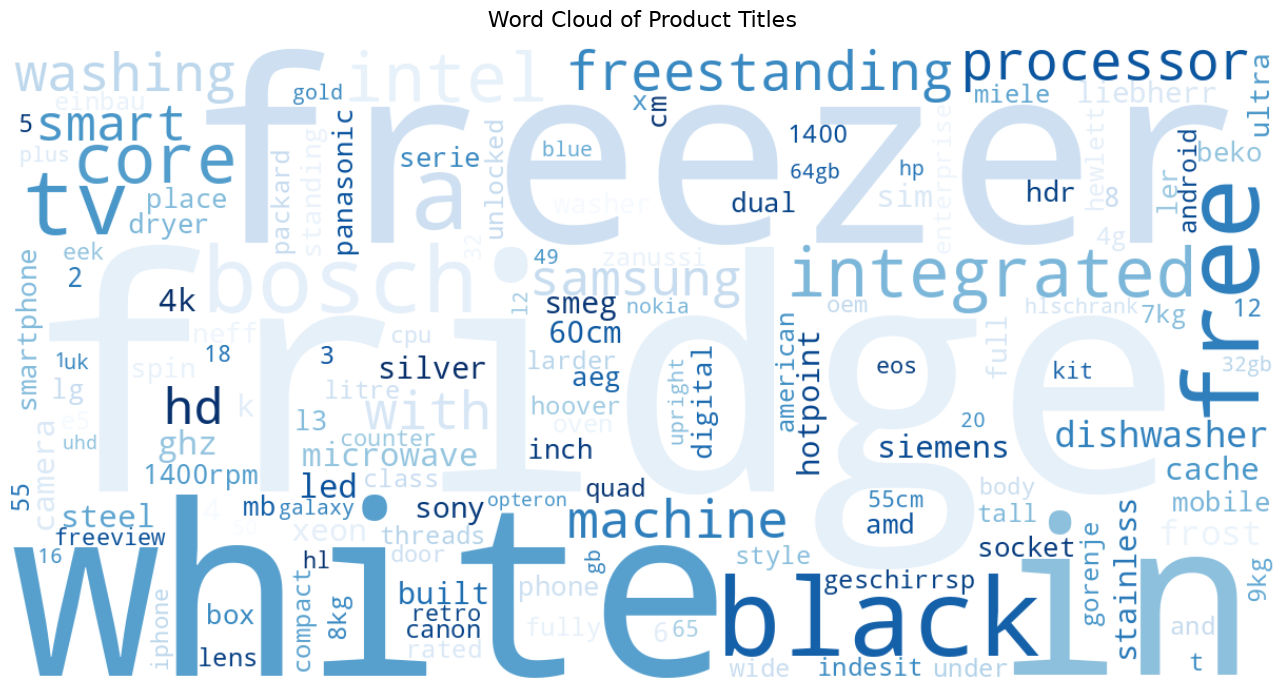

In [12]:
# Generating a word cloud from product title frequencies
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="Blues",
    max_words=150,
    collocations=False,
    random_state=42
).generate_from_frequencies(word_frequencies)

# Displaying the word cloud
plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Product Titles", fontsize=16, pad=15)
plt.tight_layout()
plt.show()

**Observations on Product Title Word Cloud:**

- Frequently occurring terms such as `fridge`, `freezer`, `white`, and `black` are prominent, reflecting common product types and attributes.
- Technical and category-specific words such as `intel`, `processor`, `washing`, and `tv` highlight the diversity of product terminology.
- The vocabulary contains both informative product descriptors and general terms, suggesting that feature extraction should emphasize discriminative words rather than frequency alone.

#### Visualizing Category-Specific Word Frequencies

In [13]:
# Calculating the top 10 words for each product category
category_word_data = []

for category, group in df.groupby(" Category Label"):
    words = " ".join(group["Product Title"].str.lower()).split()
    word_counts = Counter(words)

    for word, frequency in word_counts.most_common(10):
        category_word_data.append({
            "Category": category,
            "Word": word,
            "Frequency": frequency
        })

# Creating a dataframe for visualization
category_words_df = pd.DataFrame(category_word_data)

# Creating faceted bar charts
fig = px.bar(
    category_words_df,
    x="Frequency",
    y="Word",
    facet_col="Category",
    facet_col_wrap=2,
    orientation="h",
    color="Frequency",
    color_continuous_scale="Blues",
    title="Top 10 Most Frequent Words by Product Category",
    height=1600
)

# Customizing the chart layout
fig.update_yaxes(matches=None, showticklabels=True, autorange="reversed")
fig.update_xaxes(matches=None)
fig.update_layout(
    template="plotly_white",
    coloraxis_showscale=False,
    showlegend=False,
    margin=dict(t=100, b=50, l=100, r=40)
)

# Simplifying facet titles
fig.for_each_annotation(
    lambda annotation: annotation.update(
        text=annotation.text.split("=")[-1]
    )
)

fig.show()

**Observations on Category-Specific Word Frequencies:**

- Categories exhibit distinctive terminology, including `ghz`, `xeon`, and `processor` for CPUs; `lens` and `canon` for Digital Cameras; and `sim` and `4g` for Mobile Phones.
- Related appliance categories share vocabulary such as `fridge`, `freezer`, `frost`, and `integrated`, indicating potential challenges in distinguishing similar products.
- Category-specific technical terms provide useful classification signals, supporting the exploration of word-level and character-level TF-IDF features.

#### Visualizing Vocabulary Diversity by Category

In [14]:
# Calculating vocabulary statistics for each category
vocabulary_data = []

for category, group in df.groupby(" Category Label"):
    words = " ".join(group["Product Title"].str.lower()).split()

    vocabulary_data.append({
        "Category": category,
        "Total Words": len(words),
        "Unique Words": len(set(words)),
        "Vocabulary Diversity": len(set(words)) / len(words) * 100
    })

# Creating a vocabulary summary dataframe
vocabulary_df = pd.DataFrame(vocabulary_data)

# Sorting categories by vocabulary diversity
vocabulary_df = vocabulary_df.sort_values(
    "Vocabulary Diversity", ascending=False
)

# Creating a horizontal bar chart
fig = px.bar(
    vocabulary_df,
    x="Vocabulary Diversity",
    y="Category",
    orientation="h",
    text="Vocabulary Diversity",
    title="Vocabulary Diversity Across Product Categories",
    color="Vocabulary Diversity",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Unique Words as Percentage of Total Words",
    yaxis_title="Product Category",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=550
)

fig.show()

In [15]:
# Displaying vocabulary statistics by category
vocabulary_df.round(2)

,Category,Total Words,Unique Words,Vocabulary Diversity
3,Freezers,15954,1804,11.31
5,Fridges,26858,2814,10.48
2,Dishwashers,23321,2305,9.88
6,Microwaves,17921,1700,9.49
7,Mobile Phones,34882,3134,8.98
4,Fridge Freezers,45021,3788,8.41
8,TVs,36522,3039,8.32
9,Washing Machines,31624,2390,7.56
1,Digital Cameras,25944,1782,6.87
0,CPUs,47955,2566,5.35


**Observations on Vocabulary Diversity by Category:**

- `Freezers` exhibit the highest vocabulary diversity (**11.31%**), followed by `Fridges` (10.48%) and `Dishwashers` (9.88%).
- `CPUs` have the lowest vocabulary diversity (**5.35%**), despite containing the largest total word count (47,955), suggesting substantial repetition of technical terminology.
- Vocabulary diversity varies across categories, although differences in corpus size may influence these ratios and should be considered during interpretation.

#### Visualizing Unique Vocabulary Size by Category

In [16]:
# Sorting categories by unique vocabulary size
vocabulary_size_df = vocabulary_df.sort_values(
    "Unique Words", ascending=False
)

# Creating a horizontal bar chart
fig = px.bar(
    vocabulary_size_df,
    x="Unique Words",
    y="Category",
    orientation="h",
    text="Unique Words",
    title="Unique Vocabulary Size by Product Category",
    color="Unique Words",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Number of Unique Words",
    yaxis_title="Product Category",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=550
)

fig.show()

**Observations on Unique Vocabulary Size by Category:**

- `Fridge Freezers` have the largest vocabulary with **3,788 unique words**, followed by `Mobile Phones` (3,134) and `TVs` (3,039).
- `Microwaves` have the smallest vocabulary (**1,700 unique words**), followed by `Digital Cameras` (1,782) and `Freezers` (1,804).
- Vocabulary size varies across categories and may reflect differences in listing volumes, product specifications, and naming conventions.

#### Visualizing Product Listings per Cluster

In [17]:
# Calculating the number of listings per product cluster
cluster_sizes = df.groupby(" Cluster ID").size().reset_index(name="Listing Count")

# Creating a histogram of cluster sizes
fig = px.histogram(
    cluster_sizes,
    x="Listing Count",
    nbins=27,
    title="Distribution of Product Listings per Cluster",
    color_discrete_sequence=["#3274A1"]
)

# Customizing the chart layout
fig.update_layout(
    xaxis_title="Number of Listings per Cluster",
    yaxis_title="Number of Product Clusters",
    template="plotly_white",
    height=500,
    bargap=0.05
)

fig.show()

**Observations on Product Listings per Cluster:**

- The dataset contains **13,233 product clusters**, with an average of **2.67 listings per cluster** and a median of 2.
- **7,859 clusters (59.39%)** contain multiple listings, while 5,374 clusters (40.61%) contain only one listing.
- Cluster sizes range from **1 to 27 listings**, reinforcing the importance of group-aware splitting to prevent related product listings from appearing in both training and testing datasets.

#### Visualizing Average Cluster Size by Category

In [18]:
# Calculating the number of listings for each product cluster
category_cluster_sizes = (
    df.groupby([" Category Label", " Cluster ID"])
    .size()
    .reset_index(name="Listing Count")
)

# Calculating average cluster sizes by category
average_cluster_sizes = (
    category_cluster_sizes.groupby(" Category Label")["Listing Count"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
    .reset_index()
)

average_cluster_sizes.columns = ["Category", "Average Cluster Size"]

# Creating a horizontal bar chart
fig = px.bar(
    average_cluster_sizes,
    x="Average Cluster Size",
    y="Category",
    orientation="h",
    text="Average Cluster Size",
    title="Average Product Listings per Cluster by Category",
    color="Average Cluster Size",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Average Listings per Cluster",
    yaxis_title="Product Category",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=550
)

fig.show()

In [19]:
# Displaying average product listings per cluster by category
average_cluster_sizes

,Category,Average Cluster Size
0,Digital Cameras,3.78
1,Washing Machines,3.17
2,Microwaves,2.98
3,Freezers,2.91
4,TVs,2.78
5,Fridge Freezers,2.75
6,Fridges,2.61
7,Dishwashers,2.50
8,Mobile Phones,2.39
9,CPUs,1.96


**Observations on Average Cluster Size by Category:**

- `Digital Cameras` have the largest average cluster size (**3.78 listings**), followed by `Washing Machines` (3.17) and `Microwaves` (2.98).
- `CPUs` have the smallest average cluster size (**1.96 listings**), followed by `Mobile Phones` (2.39) and `Dishwashers` (2.50).
- Differences in cluster sizes indicate varying levels of product listing repetition across categories, reinforcing the importance of cluster-aware data splitting.

#### Visualizing Top Merchants by Product Listing Volume

In [20]:
# Calculating product listing counts for each merchant
merchant_counts = (
    df[" Merchant ID"]
    .value_counts()
    .head(15)
    .reset_index()
)

merchant_counts.columns = ["Merchant ID", "Listing Count"]
merchant_counts["Merchant ID"] = merchant_counts["Merchant ID"].astype(str)

# Creating a horizontal bar chart
fig = px.bar(
    merchant_counts,
    x="Listing Count",
    y="Merchant ID",
    orientation="h",
    text="Listing Count",
    title="Top 15 Merchants by Product Listing Volume",
    color="Listing Count",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Number of Product Listings",
    yaxis_title="Merchant ID",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=600
)

fig.show()

**Observations on Top Merchants by Product Listing Volume:**

- `Merchant ID 3` contributes the most product listings (**2,547**), followed by `Merchant ID 6` (1,591) and `Merchant ID 298` (1,523).
- Listing volumes vary considerably among merchants, with the leading merchant contributing approximately **7.21%** of all records.
- The concentration of listings among prominent merchants suggests that merchant representation may influence the dataset's category composition.

#### Visualizing Merchant Category Coverage

In [21]:
# Calculating the number of categories covered by each merchant
merchant_category_counts = (
    df.groupby(" Merchant ID")[" Category Label"]
    .nunique()
)

# Calculating the distribution of merchant category coverage
merchant_coverage = (
    merchant_category_counts
    .value_counts()
    .sort_index()
    .reset_index()
)

merchant_coverage.columns = ["Number of Categories", "Merchant Count"]

# Creating a bar chart
fig = px.bar(
    merchant_coverage,
    x="Number of Categories",
    y="Merchant Count",
    text="Merchant Count",
    title="Distribution of Product Category Coverage Across Merchants",
    color="Merchant Count",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Number of Product Categories",
    yaxis_title="Number of Merchants",
    xaxis=dict(dtick=1),
    coloraxis_showscale=False,
    template="plotly_white",
    height=500
)

fig.show()

**Observations on Merchant Category Coverage:**

- **139 merchants (45.42%)** specialize in a single product category, while **167 merchants (54.58%)** list products across multiple categories.
- Merchants cover an average of **3.09 categories**, with only **4 merchants** representing all 10 product categories.
- The variation in category coverage suggests that merchant specialization may influence product category representation.

#### Visualizing Merchant Distribution Across Product Categories

In [22]:
# Calculating the number of unique merchants in each category
category_merchants = (
    df.groupby(" Category Label")[" Merchant ID"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index()
)

category_merchants.columns = ["Category", "Unique Merchants"]

# Creating a horizontal bar chart
fig = px.bar(
    category_merchants,
    x="Unique Merchants",
    y="Category",
    orientation="h",
    text="Unique Merchants",
    title="Number of Unique Merchants by Product Category",
    color="Unique Merchants",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Number of Unique Merchants",
    yaxis_title="Product Category",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=550
)

fig.show()

In [23]:
# Displaying the number of unique merchants in each category
category_merchants

,Category,Unique Merchants
0,TVs,129
1,Microwaves,114
2,Fridges,104
3,Digital Cameras,103
4,Fridge Freezers,101
5,Dishwashers,94
6,Freezers,93
7,Washing Machines,87
8,Mobile Phones,84
9,CPUs,37


**Observations on Merchant Distribution Across Product Categories:**

- `TVs` have the highest merchant participation (**129 merchants**), followed by `Microwaves` (114) and `Fridges` (104).
- `CPUs` have the lowest merchant participation (**37 merchants**), followed by `Mobile Phones` (84) and `Washing Machines` (87).
- Merchant coverage varies considerably across categories, suggesting differences in seller participation and category specialization.

#### Visualizing Merchant Concentration by Product Category

In [24]:
# Calculating listing counts for each merchant within each category
merchant_category_listings = (
    df.groupby([" Category Label", " Merchant ID"])
    .size()
    .reset_index(name="Listing Count")
)

# Identifying the largest merchant contribution in each category
top_merchant_listings = (
    merchant_category_listings.groupby(" Category Label")["Listing Count"]
    .max()
)

# Calculating total listings per category
total_category_listings = df[" Category Label"].value_counts()

# Calculating the largest merchant's share of each category
merchant_concentration = (
    (top_merchant_listings / total_category_listings * 100)
    .sort_values(ascending=False)
    .reset_index()
)

merchant_concentration.columns = ["Category", "Top Merchant Share"]

# Creating a horizontal bar chart
fig = px.bar(
    merchant_concentration,
    x="Top Merchant Share",
    y="Category",
    orientation="h",
    text="Top Merchant Share",
    title="Largest Merchant's Share of Listings by Product Category",
    color="Top Merchant Share",
    color_continuous_scale="Blues"
)

# Customizing the chart layout
fig.update_traces(
    texttemplate="%{text:.2f}%",
    textposition="outside",
    cliponaxis=False
)

fig.update_layout(
    xaxis_title="Share of Category Listings (%)",
    yaxis_title="Product Category",
    yaxis=dict(autorange="reversed"),
    coloraxis_showscale=False,
    template="plotly_white",
    height=550
)

fig.show()

In [25]:
# Displaying the largest merchant's listing share in each category
merchant_concentration.round(2)

,Category,Top Merchant Share
0,Mobile Phones,17.62
1,CPUs,14.86
2,Dishwashers,13.81
3,Digital Cameras,11.94
4,Fridges,10.74
5,Microwaves,7.77
6,TVs,7.35
7,Washing Machines,7.27
8,Freezers,7.01
9,Fridge Freezers,6.78


**Observations on Merchant Concentration by Product Category:**

- `Mobile Phones` show the highest merchant concentration (**17.62%**), followed by `CPUs` (14.86%) and `Dishwashers` (13.81%).
- `Fridge Freezers` have the lowest concentration (**6.78%**), followed by `Freezers` (7.01%) and `Washing Machines` (7.27%).
- No category has a single merchant contributing more than **18%** of its listings, although merchant concentration varies across categories.

#### Identifying Product Titles with Conflicting Category Labels

In [26]:
# Identifying product titles assigned to multiple categories
title_category_counts = (
    df.groupby("Product Title")[" Category Label"]
    .nunique()
)

# Selecting titles with conflicting category labels
conflicting_titles = title_category_counts[
    title_category_counts > 1
].index

# Retrieving the corresponding product records
conflicting_records = (
    df[df["Product Title"].isin(conflicting_titles)]
    [["Product Title", " Cluster ID", " Category Label"]]
    .sort_values("Product Title")
    .reset_index(drop=True)
)

# Displaying the conflicting product records
print(f"Number of conflicting product titles: {len(conflicting_titles)}")
print(f"Number of affected records: {len(conflicting_records)}")

display(conflicting_records)

Number of conflicting product titles: 2
Number of affected records: 4


,Product Title,Cluster ID,Category Label
0,blomberg kgm9550 fridge freezer,46085,Fridge Freezers
1,blomberg kgm9550 fridge freezer,47395,Fridges
2,bosch kur15a50gb integrated undercounter fridge,42819,Washing Machines
3,bosch kur15a50gb integrated undercounter fridge,46113,Fridges


**Observations on Product Titles with Conflicting Category Labels:**

- **2 identical product titles**, representing **4 records**, are assigned to different product categories.
- The `Blomberg KGM9550` product appears under both `Fridge Freezers` and `Fridges`, while the `Bosch KUR15A50GB` fridge appears under `Washing Machines` and `Fridges`.
- These inconsistencies introduce conflicting target labels for identical input text and should be resolved during data preparation to improve label consistency.

#### Analyzing Product Titles Across Multiple Clusters

In [27]:
# Calculating the number of unique clusters associated with each product title
title_cluster_counts = (
    df.groupby("Product Title")[" Cluster ID"]
    .nunique()
)

# Identifying titles associated with multiple clusters
multi_cluster_titles = title_cluster_counts[
    title_cluster_counts > 1
]

# Summarizing cross-cluster title repetition
print(f"Total unique product titles: {title_cluster_counts.size:,}")
print(f"Titles appearing in multiple clusters: {len(multi_cluster_titles):,}")
print(f"Percentage of unique titles appearing in multiple clusters: {len(multi_cluster_titles) / title_cluster_counts.size * 100:.2f}%")
print(f"Maximum clusters associated with one title: {title_cluster_counts.max()}")

# Displaying the distribution of cluster counts per title
cluster_repetition_distribution = (
    multi_cluster_titles
    .value_counts()
    .sort_index()
    .reset_index()
)

cluster_repetition_distribution.columns = ["Number of Clusters", "Number of Titles"]

display(cluster_repetition_distribution)

Total unique product titles: 30,993
Titles appearing in multiple clusters: 617
Percentage of unique titles appearing in multiple clusters: 1.99%
Maximum clusters associated with one title: 90


,Number of Clusters,Number of Titles
0,2,396
1,3,107
2,4,45
3,5,28
4,6,13
5,7,6
6,8,5
7,9,6
8,11,3
9,15,1


**Observations on Product Titles Across Multiple Clusters:**

- **617 unique product titles** appear in multiple clusters, indicating that identical product descriptions can be associated with different cluster identifiers.
- Most cross-cluster repetitions are limited to **2 clusters (396 titles)** or **3 clusters (107 titles)**, although one title appears across **90 clusters**.
- A cluster-aware split alone cannot guarantee that identical titles remain within the same dataset partition, highlighting the need for additional title-level leakage prevention during data preparation.

#### Inspecting the Most Repeated Cross-Cluster Product Titles

In [29]:
# Identifying the 15 product titles appearing across the most clusters
top_cross_cluster_titles = (
    title_cluster_counts
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

top_cross_cluster_titles.columns = ["Product Title", "Number of Clusters"]

# Adding the number of listings associated with each title
title_listing_counts = df["Product Title"].value_counts()

top_cross_cluster_titles["Number of Listings"] = (
    top_cross_cluster_titles["Product Title"]
    .map(title_listing_counts)
)

# Adding the number of distinct categories associated with each title
top_cross_cluster_titles["Number of Categories"] = (
    top_cross_cluster_titles["Product Title"]
    .map(title_category_counts)
)

# Displaying the results
display(top_cross_cluster_titles)

,Product Title,Number of Clusters,Number of Listings,Number of Categories
0,washing machine,90,90,1
1,built in fully integrated dishwasher,35,35,1
2,frost free fridge freezer,34,34,1
3,washer dryer,24,24,1
4,american fridge freezer,22,22,1
5,static integrated fridge freezer,18,18,1
6,static fridge freezer,17,17,1
7,built in semi integrated dishwasher,15,15,1
8,1400rpm washing machine 8kg load class a white,11,11,1
9,frost free integrated fridge freezer,11,11,1


**Observations on the Most Repeated Cross-Cluster Product Titles:**

- Generic descriptions such as `washing machine` (**90 clusters**), `built in fully integrated dishwasher` (35), and `frost free fridge freezer` (34) account for the highest cross-cluster repetition.
- All 15 frequently repeated titles belong to a single category each, indicating that their repetition does not introduce conflicting category labels.
- Repeated generic titles across independent clusters reinforce the need to prevent identical product titles from appearing in both training and testing datasets.

### Key EDA Findings and Modeling Implications

The exploratory analysis of 35,311 product listings across 10 categories highlights several important characteristics of the dataset.

**Key Findings:**

1. **Category Distribution:** Product categories are moderately imbalanced, with `Fridge Freezers` representing the largest share (15.58%) and `Freezers` the smallest (6.26%).

2. **Product Title Characteristics:** Titles average 8.67 words and 52.98 characters. Approximately 95% contain numerical information, highlighting the importance of preserving model numbers and technical specifications during text preprocessing.

3. **Category-Specific Vocabulary:** Product categories exhibit distinctive terminology, supporting the use of word-level and character-level TF-IDF features for classification.

4. **Product Cluster Structure:** The dataset contains 13,233 product clusters, including 7,859 clusters with multiple listings. Repeated listings require careful handling to avoid overly optimistic model evaluation.

5. **Merchant Representation:** The dataset includes 306 merchants, with differences in listing volume, category coverage, and merchant concentration across product categories.

6. **Data Quality and Leakage Risks:** Two product titles have conflicting category labels, while 617 unique titles appear across multiple clusters. These issues require label consistency checks and leakage-aware dataset splitting.

**Modeling Implications:**

- Preserve informative product terminology, numerical specifications, and model identifiers during preprocessing.
- Explore word-level and character-level TF-IDF representations to capture both product terminology and variations in model names.
- Resolve conflicting category labels and prevent cluster or identical-title overlap between training and testing partitions.
- Evaluate multiclass classification models using macro F1-score, alongside accuracy and category-level precision and recall.
- Save cleaned datasets, train/test partitions, and fitted preprocessing artifacts to support reproducible model development and evaluation.

Overall, the EDA establishes a foundation for building a reliable product category classification pipeline while addressing the dataset's text characteristics, class distribution, and potential information leakage.